## Explanations via CRAFT

[Concept Recursive Activation Factorisation (CRAFT)](https://arxiv.org/pdf/2211.10154.pdf)

In [1]:
import sys
sys.path.append('./wingbeats/')
sys.path.append('./Craft/')

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-09-14 14:59:10.206590: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-09-14 14:59:10.745068: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
bees_subfolder = '5_species/'
dataset_folder = 'Bees_Christian_masked_bbox/Whole/'
metafolder = './beexplainable/metafiles/Bees_Christian/'

BEES_PATH = '../data/Wildbienen/' + dataset_folder
IMAGES_PATH = metafolder + 'images_5.txt'
IMAGES_LABELS_PATH = metafolder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + bees_subfolder + 'classes.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/'

## Load images

In [5]:
batch_size = 64
img_height = img_width = 224

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_dict = {k: img_dict[k] for k in list(img_dict)[:30]} # only select samples from first species
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
img_label_dict = {k: img_label_dict[k] for k in list(img_label_dict)[:30]} # only select samples from first species
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

2023-09-14 14:59:10.801316: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().shuffle(len(y_true)).batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

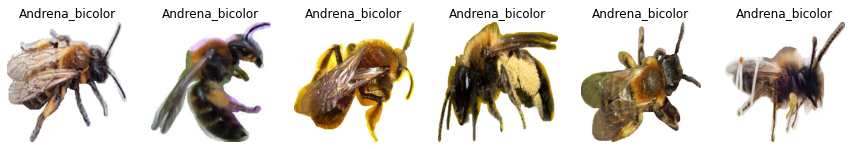

In [9]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [10]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(30, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


## Load Model

In [11]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4 # lr and reg optimized in HPO notebook

constructor =  wm.build_simple_classifier
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'

out_shape = len(classes)
model_name = 'ResNet50_' + init + '_' + input_form + '_5spec_2' # model was trained on raw whole dataset
weights_file = MODELS_PATH + 'all/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not (must be set to True even if just loading weights and doing inference)
trainable = True

Model loaded from ./beexplainable/models/all/5_species/ResNet50_iNat_masked_bbox_5spec_2/ResNet50_iNat_masked_bbox_5spec_2.h5


In [12]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

In [15]:
# Cut the model in two parts (as explained in the paper)
# First part is g(.) our 'input_to_latent' model, second part is h(.) our 'latent_to_logit' model
# Note: it is strongly recommended to provide CRAFT with the layer before the global average pooling.
g = tf.keras.Model(model.layers[1].resnet.input, model.layers[1].resnet.layers[-2].output)

inp = model.layers[1].resnet.layers[-1].input
x = tf.keras.layers.GlobalAveragePooling2D()(inp)
x = model.layers[2](x)
out = model.layers[3](x)
h = tf.keras.Model(inp, out)

## Apply CRAFT

In [17]:
from craft.craft_tf import Craft

craft = Craft(input_to_latent = g,
              latent_to_logit = h,
              number_of_concepts = 10,
              patch_size = 80,
              batch_size = 30)

In [18]:
# Craft requires images as numpy arrays
for test_imgs, test_labs in test_set.as_numpy_iterator():
    pass
print(test_imgs.shape)

(30, 224, 224, 3)


In [19]:
# Now we can start fit the concept using our rabbit images
# CRAFT will (1) create the patches, (2) find the concept
# and (3) return the crops (crops), the embedding of the crops (crops_u), and the concept bank (w)
crops, crops_u, w = craft.fit(test_imgs)

crops.shape, crops_u.shape, w.shape

2023-09-14 15:12:43.343756: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-09-14 15:12:43.827578: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-09-14 15:12:43.828682: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-09-14 15:12:43.828693: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-09-14 15:12:43.829650: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-09-14 15:12:43.829797: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
/home/tchiaburu/anaconda3/envs/tf2_8_gpu/lib/python3.10/site-pa

(TensorShape([270, 80, 80, 3]),
 TensorShape([270, 10]),
 TensorShape([10, 2048]))

Estimate concept importance via Sobol indices

In [20]:
importances = craft.estimate_importance(test_imgs,
                                        class_id=np.unique(y_true)[0]) # index of the only selected class
images_u = craft.transform(test_imgs)

images_u.shape

TensorShape([30, 7, 7, 10])

Concept 1  has an importance value of  0.48010284
Concept 6  has an importance value of  0.12702635
Concept 2  has an importance value of  0.07181778
Concept 8  has an importance value of  0.030633837
Concept 5  has an importance value of  0.02523811


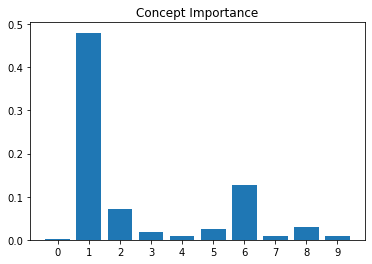

In [21]:
# Which concepts matter the most?
plt.bar(range(len(importances)), importances)
plt.xticks(range(len(importances)))
plt.title("Concept Importance")

most_important_concepts = np.argsort(importances)[::-1][:5]

for c_id in most_important_concepts:
  print("Concept", c_id, " has an importance value of ", importances[c_id])

Concept 1  has an importance value of  0.48010284


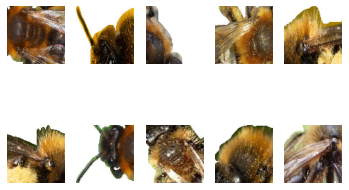




Concept 6  has an importance value of  0.12702635


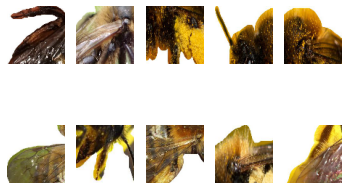




Concept 2  has an importance value of  0.07181778


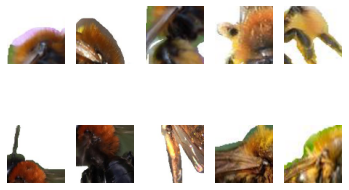




Concept 8  has an importance value of  0.030633837


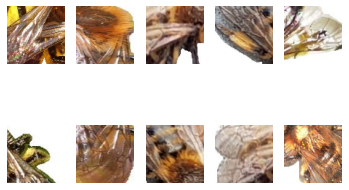




Concept 5  has an importance value of  0.02523811


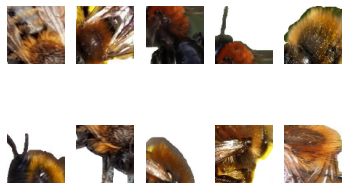

In [22]:
# Inspect those concepts by showing the 10 best crops for each of them
from math import ceil
nb_crops = 10

def show(img):
  img = np.array(img)
  img -= img.min();img /= img.max()
  plt.imshow(img); plt.axis('off')

for c_id in most_important_concepts:

  best_crops_ids = np.argsort(crops_u[:, c_id])[::-1][:nb_crops]
  best_crops = np.array(crops)[best_crops_ids]

  print("Concept", c_id, " has an importance value of ", importances[c_id])
  for i in range(nb_crops):
    plt.subplot(ceil(nb_crops/5), 5, i+1)
    show(best_crops[i])
  plt.show()
  print('\n\n')

In [23]:
from matplotlib.colors import ListedColormap
import matplotlib
import colorsys

def get_alpha_cmap(cmap):
  if isinstance(cmap, str):
    cmap = plt.get_cmap(cmap)
  else:
    c = np.array((cmap[0]/255.0, cmap[1]/255.0, cmap[2]/255.0))

    cmax = colorsys.rgb_to_hls(*c)
    cmax = np.array(cmax)
    cmax[-1] = 1.0

    cmax = np.clip(np.array(colorsys.hls_to_rgb(*cmax)), 0, 1)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", [c,cmax])

  alpha_cmap = cmap(np.arange(256))
  alpha_cmap[:,-1] = np.linspace(0, 0.85, 256)
  alpha_cmap = ListedColormap(alpha_cmap)

  return alpha_cmap

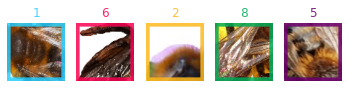

In [24]:
cmaps = [
  get_alpha_cmap((54, 197, 240)),
  get_alpha_cmap((210, 40, 95)),
  get_alpha_cmap((236, 178, 46)),
  get_alpha_cmap((15, 157, 88)),
  get_alpha_cmap((84, 25, 85))
]

def show(img, **kwargs):
  img = np.array(img)
  if img.shape[0] == 3:
    img = img.transpose(1, 2, 0)

  img -= img.min();img /= img.max()
  plt.imshow(img, **kwargs); plt.axis('off')


def plot_legend():
  for i, c_id in enumerate(most_important_concepts):
    cmap = cmaps[i]
    plt.subplot(1, len(most_important_concepts), i+1)

    best_crops_id = np.argsort(crops_u[:, c_id])[::-1][0]
    best_crop = crops[best_crops_id]

    p = 5
    mask = np.zeros(best_crop.shape[:-1])
    mask[:p, :] = 1.0
    mask[:, :p] = 1.0
    mask[-p:, :] = 1.0
    mask[:, -p:] = 1.0

    show(best_crop)
    show(mask, cmap=cmap)
    plt.title(f"{c_id}", color=cmap(1.0))

  plt.show()

plot_legend()

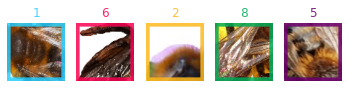

/tmp/ipykernel_3241161/2811156790.py:14: RuntimeWarning: invalid value encountered in divide
  img -= img.min();img /= img.max()


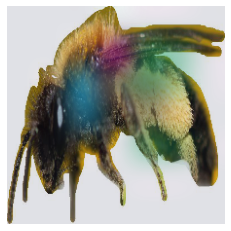

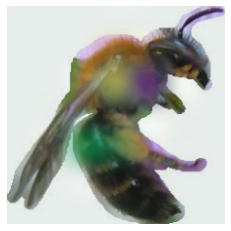

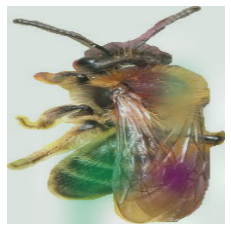

In [25]:
def concept_attribution_maps(id, percentile=95):
  img = test_imgs[id]
  u = images_u[id]

  show(img)

  for i, c_id in enumerate(most_important_concepts):

    cmap = cmaps[i]
    heatmap = u[:, :, c_id]

    # Only show concept if it exceeds N-th percentile
    sigma = np.percentile(np.array(images_u[:,:,:,c_id]).flatten(), percentile)
    heatmap = heatmap * np.array(heatmap > sigma, np.float32)

    heatmap = tf.image.resize(heatmap[:, :, None], (224, 224), method="bicubic")
    show(heatmap, cmap=cmap, alpha=0.7)

  plt.show()

plot_legend()
concept_attribution_maps(0)
plt.show()
concept_attribution_maps(1)
plt.show()
concept_attribution_maps(2)
plt.show()